In [171]:


import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

print("Libraries Imported Successfully ✅")

Libraries Imported Successfully ✅


In [172]:


df = pd.read_csv("/kaggle/input/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020/ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [173]:
print("Rows and Columns")
print(df.shape)

Rows and Columns
(10000, 14)


In [174]:
print(df.columns)

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')


In [175]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [176]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [177]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [178]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

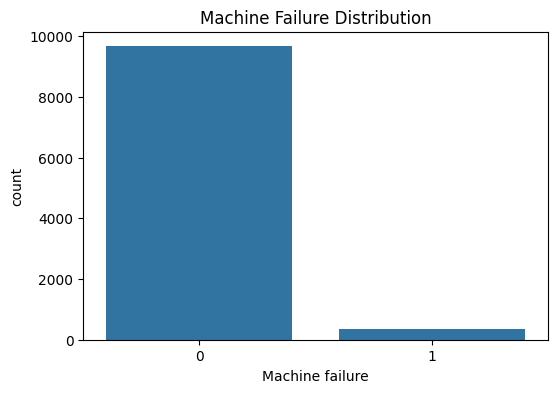

In [179]:
plt.figure(figsize=(6,4))

sns.countplot(x="Machine failure", data=df)

plt.title("Machine Failure Distribution")

plt.show()

In [180]:
failure_columns = ["TWF","HDF","PWF","OSF","RNF"]

for col in failure_columns:
    print(col)
    print(df[col].value_counts())
    print("-"*30)

TWF
TWF
0    9954
1      46
Name: count, dtype: int64
------------------------------
HDF
HDF
0    9885
1     115
Name: count, dtype: int64
------------------------------
PWF
PWF
0    9905
1      95
Name: count, dtype: int64
------------------------------
OSF
OSF
0    9902
1      98
Name: count, dtype: int64
------------------------------
RNF
RNF
0    9981
1      19
Name: count, dtype: int64
------------------------------


EDA

In [181]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


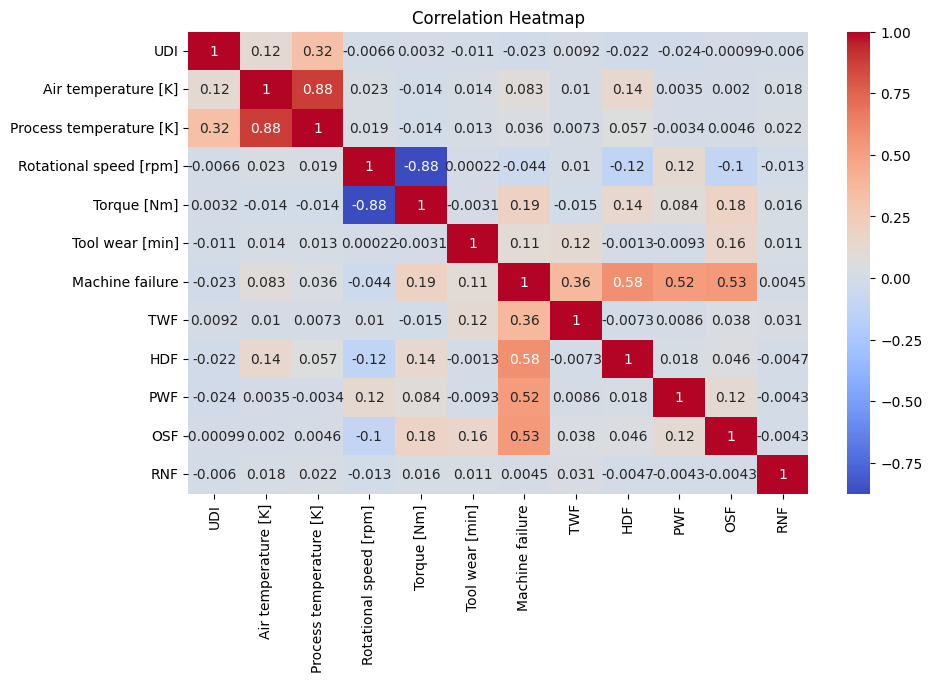

In [182]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

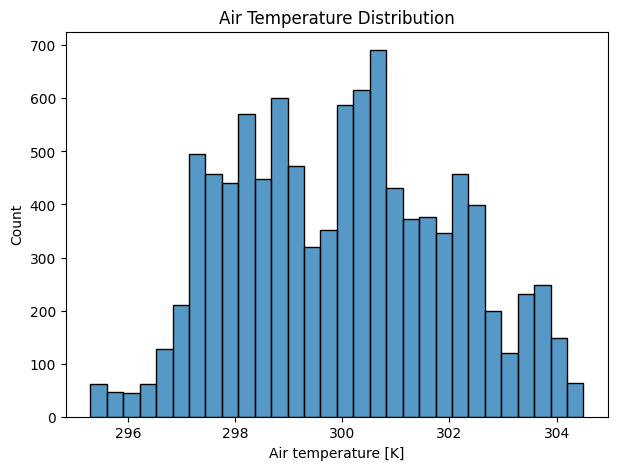

In [183]:
plt.figure(figsize=(7,5))
sns.histplot(df["Air temperature [K]"], bins=30)
plt.title("Air Temperature Distribution")
plt.show()

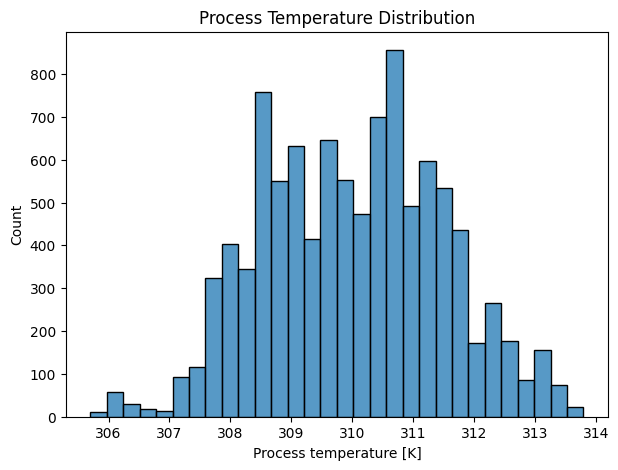

In [184]:
plt.figure(figsize=(7,5))
sns.histplot(df["Process temperature [K]"], bins=30)
plt.title("Process Temperature Distribution")
plt.show()

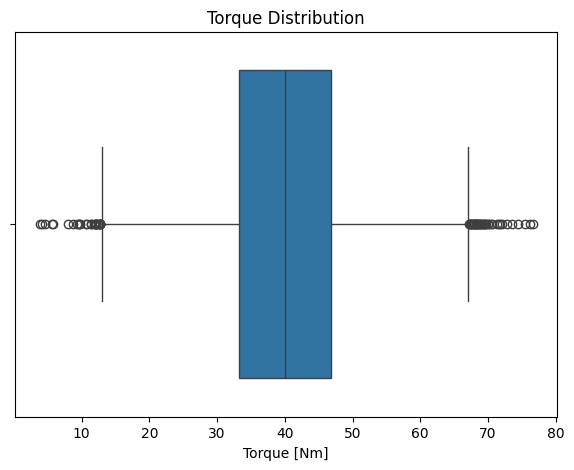

In [185]:
plt.figure(figsize=(7,5))
sns.boxplot(x=df["Torque [Nm]"])
plt.title("Torque Distribution")
plt.show()

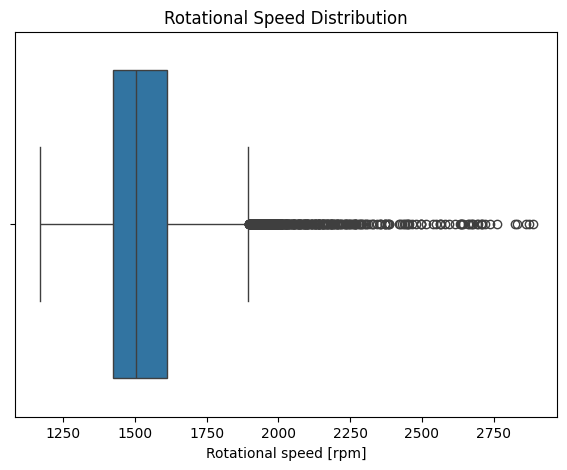

In [186]:
plt.figure(figsize=(7,5))
sns.boxplot(x=df["Rotational speed [rpm]"])
plt.title("Rotational Speed Distribution")
plt.show()

DATA PREPROCESSING

In [187]:

df = df.drop(['UDI', 'Product ID'], axis=1)

df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [188]:

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["Type"] = encoder.fit_transform(df["Type"])

df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,2,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,1,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,1,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,1,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,1,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [189]:
X = df.drop("Machine failure", axis=1)

y = df["Machine failure"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (10000, 11)
Target Shape: (10000,)


In [190]:
print(y.value_counts())

Machine failure
0    9661
1     339
Name: count, dtype: int64


apply SMOTE

In [191]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X, y)

print("Before SMOTE:")
print(y.value_counts())

print("\nAfter SMOTE:")
print(y_resampled.value_counts())

Before SMOTE:
Machine failure
0    9661
1     339
Name: count, dtype: int64

After SMOTE:
Machine failure
0    9661
1    9661
Name: count, dtype: int64


Train-Test Split

In [192]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled,
    y_resampled,
    test_size=0.2,
    random_state=42,
    stratify=y_resampled
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (15457, 11)
Testing Data: (3865, 11)


In [193]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Data Scaled Successfully!")

Data Scaled Successfully!


baseline model

In [194]:
from sklearn.ensemble import IsolationForest

iso_model = IsolationForest(
    contamination=0.05,
    random_state=42
)

iso_model.fit(X_train_scaled)

print("Isolation Forest Model Trained Successfully!")

Isolation Forest Model Trained Successfully!


In [195]:
iso_predictions = iso_model.predict(X_test_scaled)


iso_predictions = [1 if x == -1 else 0 for x in iso_predictions]

print("Predictions Completed!")

Predictions Completed!


In [196]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report")
print(classification_report(y_test, iso_predictions))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, iso_predictions))

Classification Report
              precision    recall  f1-score   support

           0       0.53      1.00      0.69      1933
           1       0.99      0.11      0.19      1932

    accuracy                           0.55      3865
   macro avg       0.76      0.55      0.44      3865
weighted avg       0.76      0.55      0.44      3865


Confusion Matrix
[[1931    2]
 [1725  207]]


In [197]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_scaled, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [198]:
rf_predictions = rf_model.predict(X_test_scaled)

print("Prediction Completed!")

Prediction Completed!


In [199]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report")
print(classification_report(y_test, rf_predictions))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, rf_predictions))

Classification Report
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1933
           1       0.98      0.98      0.98      1932

    accuracy                           0.98      3865
   macro avg       0.98      0.98      0.98      3865
weighted avg       0.98      0.98      0.98      3865


Confusion Matrix
[[1890   43]
 [  41 1891]]


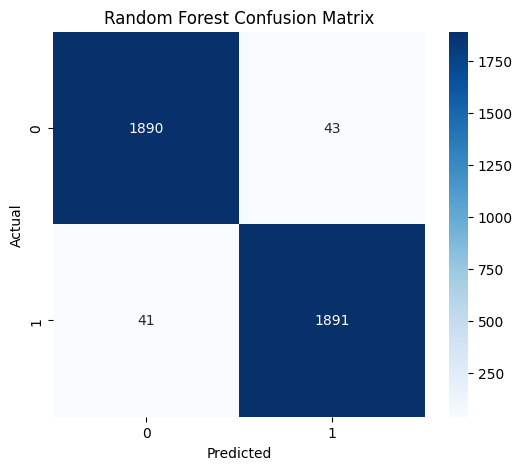

In [200]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## Model Comparison

| Model | Precision | Recall | F1-Score |
|--------|-----------|---------|----------|
| Isolation Forest | (your result) | (your result) | (your result) |
| Random Forest | (your result) | (your result) | (your result) |

Observation:
Random Forest performs significantly better than Isolation Forest because it is a supervised learning model trained on labeled data.

                    Feature  Importance
4               Torque [Nm]    0.232722
3    Rotational speed [rpm]    0.221254
5           Tool wear [min]    0.155184
8                       PWF    0.083262
7                       HDF    0.069228
6                       TWF    0.064023
1       Air temperature [K]    0.059178
9                       OSF    0.045552
2   Process temperature [K]    0.041018
0                      Type    0.028413
10                      RNF    0.000165


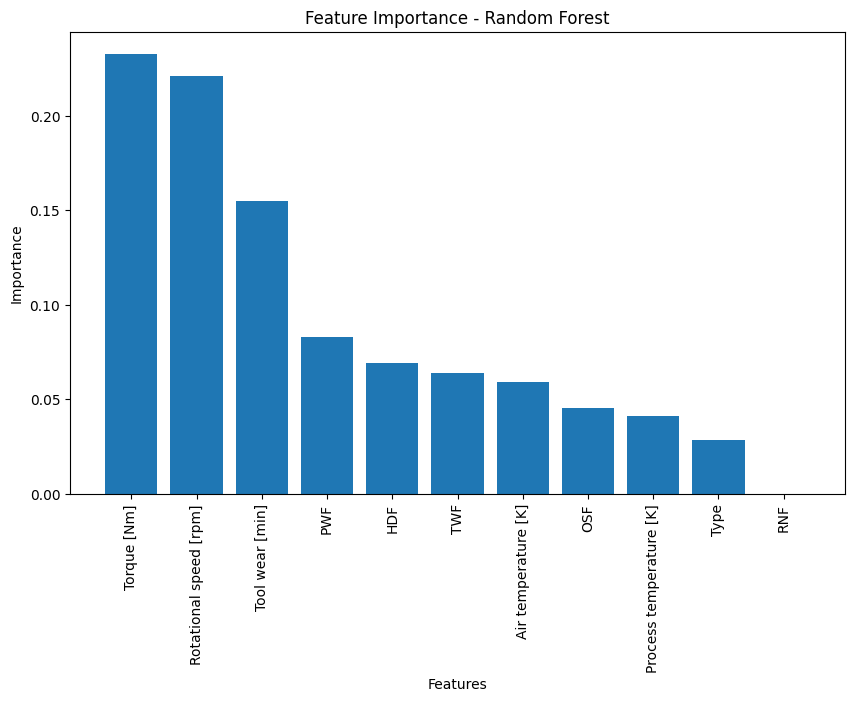

In [201]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print(feature_importance)

plt.figure(figsize=(10,6))
plt.bar(feature_importance['Feature'], feature_importance['Importance'])
plt.xticks(rotation=90)
plt.title("Feature Importance - Random Forest")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

plt.show()

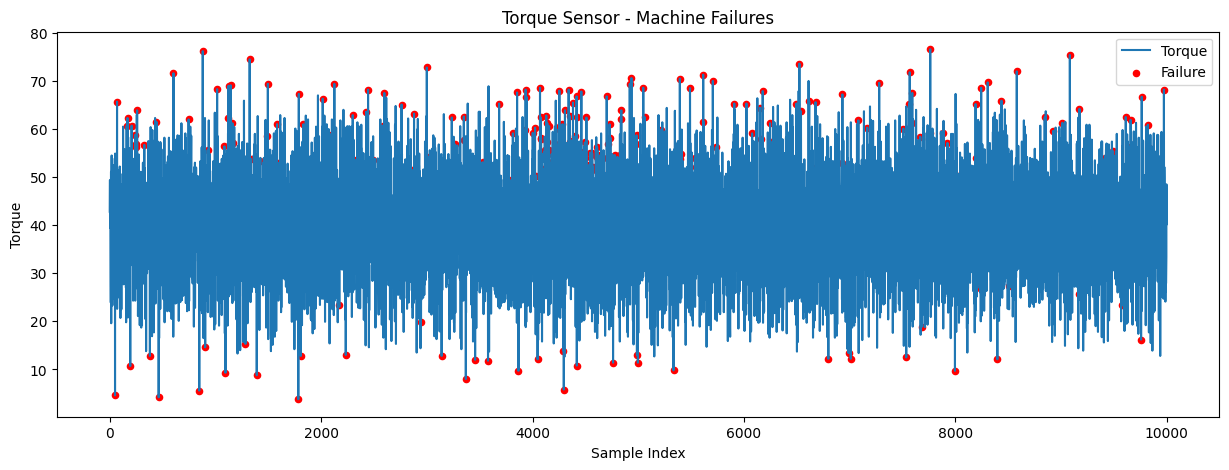

In [202]:
plt.figure(figsize=(15,5))

plt.plot(df.index, df["Torque [Nm]"], label="Torque")

anomaly_index = df[df["Machine failure"] == 1].index

plt.scatter(
    anomaly_index,
    df.loc[anomaly_index, "Torque [Nm]"],
    color="red",
    label="Failure",
    s=20
)

plt.title("Torque Sensor - Machine Failures")
plt.xlabel("Sample Index")
plt.ylabel("Torque")
plt.legend()

plt.show()

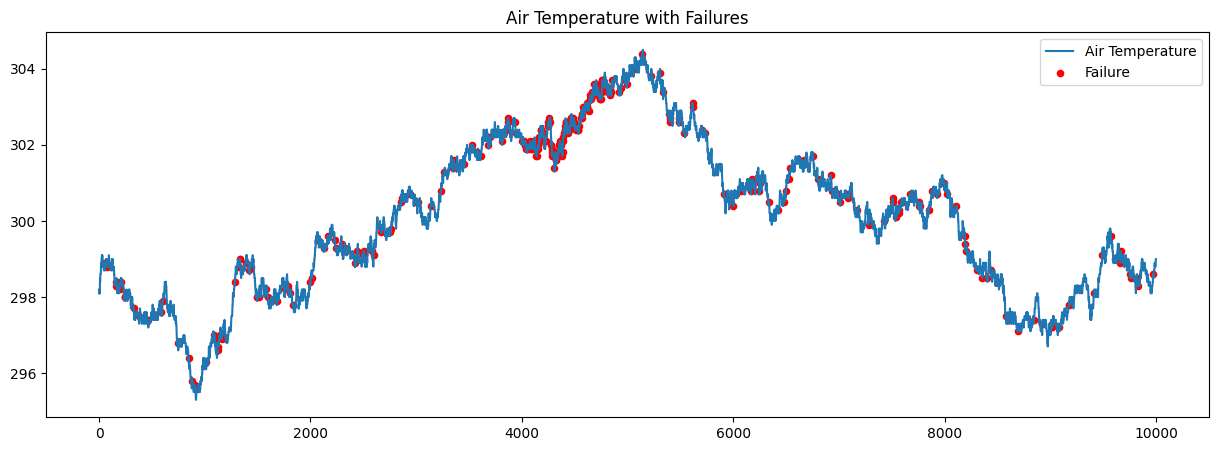

In [203]:
plt.figure(figsize=(15,5))

plt.plot(df.index, df["Air temperature [K]"], label="Air Temperature")

plt.scatter(
    anomaly_index,
    df.loc[anomaly_index, "Air temperature [K]"],
    color="red",
    s=20,
    label="Failure"
)

plt.title("Air Temperature with Failures")
plt.legend()

plt.show()